<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl;">

# 📊 تقرير تحليل سوق المطاعم وتفضيلات الزبائن
## مشروع استكشافي لتحديد الفرص الاستثمارية (Restaurant Market Analysis)

<hr>

### 📝 1. مقدمة عن المشروع (Project Overview)
يهدف هذا التقرير إلى دراسة وتحليل مجموعة بيانات حقيقية لسوق المطاعم. تم التركيز على فهم سلوك المستهلكين، ومعرفة مدى تأثير <b>الفئات السعرية</b> و<b>خدمات التوصيل الإلكتروني</b> على تقييمات رضا الزبائن، بالإضافة إلى تحديد <b>المدن والمطابخ الأعلى أداءً</b> لدعم صناع القرار والمستثمرين.

### 🛠️ 2. خطوات تجهيز وتنظيف البيانات (Data Cleaning & Preparation)
قبل البدء بالتحليل، تم فحص البيانات والقيام بالخطوات التالية لضمان دقة النتائج:
• <b>تعديل أنواع البيانات:</b> التأكد من قراءة الأسعار والتقييمات كأرقام (<code dir="ltr">int64</code> و <code dir="ltr">float64</code>).
<br>
• <b>معالجة القيم المفقودة:</b> ملء الفراغات في عمود المطابخ بـ <b>Unknown</b>.
<br>
• <b>التعامل مع التقييمات الصفرية:</b> تم اكتشاف <b>2,148 مطعماً</b> بتقييم <b>0</b> (مطاعم جديدة/غير مقيمة)، وتم عزلها في متغير جديد <code dir="ltr">df_rated</code> للحفاظ على دقة المتوسطات الحسابية لرضا الزبائن.

</div>


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# قراءة البيانات وفلترة الأصفار
df = pd.read_csv("D:\\Zomato Restaurant Dataset.csv",encoding='utf-8')
df['Cuisines'] = df['Cuisines'].fillna('Unknown')
df_rated = df[df['Aggregate rating'] > 0].copy()

print(f"تم تجهيز البيانات بنجاح. عدد المطاعم الخاضعة لتحليل الجودة: {df_rated.shape[0]} مطعم.")


تم تجهيز البيانات بنجاح. عدد المطاعم الخاضعة لتحليل الجودة: 7403 مطعم.


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl;">

<hr>

### 💵 3. تحليل الفئات السعرية وحجم التفاعل (Price Range Analysis)
في هذه الخطوة، قمنا ببحث العلاقة بين الفئة السعرية للمطعم (من <b>1: اقتصادي</b> إلى <b>4: فاخر جداً</b>) ومتوسط التقييم وعدد الأصوات المستلمة.

</div>


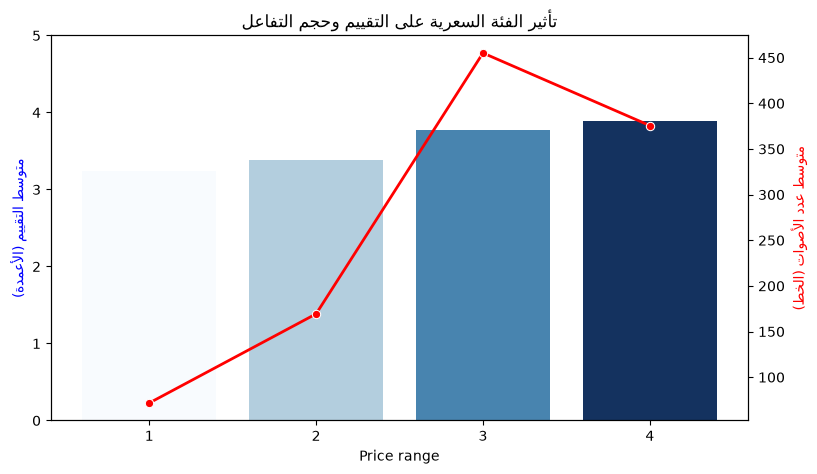

,Price range,Aggregate rating,Votes
0,1,3.238885,71.713192
1,2,3.377167,169.347473
2,3,3.777276,455.142025
3,4,3.890957,375.624348


In [27]:
# كود حساب متوسط التقييم والأصوات للفئات السعرية
price_analysis = df_rated.groupby('Price range')[['Aggregate rating', 'Votes']].mean().reset_index()

# رسم البيان المزدوج
fig, ax1 = plt.subplots(figsize=(9, 5))
sns.barplot(x='Price range', y='Aggregate rating', data=price_analysis, ax=ax1, palette='Blues', hue='Price range', legend=False)
ax1.set_ylabel('متوسط التقييم (الأعمدة)', color='blue')
ax1.set_ylim(0, 5)

ax2 = ax1.twinx()
sns.lineplot(x=price_analysis.index, y=price_analysis['Votes'], ax=ax2, color='red', marker='o', linewidth=2)
ax2.set_ylabel('متوسط عدد الأصوات (الخط)', color='red')

plt.title('تأثير الفئة السعرية على التقييم وحجم التفاعل')
plt.show()

# عرض الجدول
price_analysis


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl; line-height: 1.6;">

<b>💡 أهم الاستنتاجات التجارية (<span dir="ltr">Insights</span>):</b>

• هناك <b>علاقة طردية واضحة</b>؛ فالمطاعم الفاخرة (الفئة <span dir="ltr"><b>4</b></span>) تحقق أعلى تقييم رضا لعملائها بمتوسط (<span dir="ltr"><b>3.89</b></span>).
<br>
• الفئة السعرية (<span dir="ltr"><b>3</b></span>) تمثل <b>المنطقة الذهبية (<span dir="ltr">Sweet Spot</span>)</b> في السوق، حيث سجلت أعلى تفاعل وإقبال جماهيري على الإطلاق بمتوسط <span dir="ltr"><b>455</b></span> صوتاً للمطعم الواحد وبتقييم مرتفع جداً (<span dir="ltr"><b>3.77</b></span>).

</div>


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl; line-height: 1.6;">

<hr>

### 🛵 4. معضلة خدمة التوصيل الإلكتروني (<span dir="ltr">Has Online Delivery</span>)

تم اختبار الفرضية الشائعة: <i>"هل توفير خدمة التوصيل يرفع دائماً من تقييم المطعم؟"</i>، وقمنا بعمل مصفوفة متقدمة تربط السعر بالتوصيل.

</div>


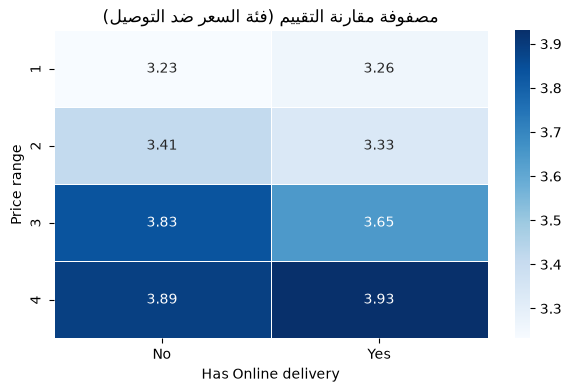

In [28]:
# كود المصفوفة المتقدمة والرسم الحراري
pivot_analysis = df_rated.pivot_table(index='Price range', 
                                      columns='Has Online delivery', 
                                      values='Aggregate rating', 
                                      aggfunc='mean')

plt.figure(figsize=(7, 4))
sns.heatmap(pivot_analysis, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5)
plt.title('مصفوفة مقارنة التقييم (فئة السعر ضد التوصيل)')
plt.show()


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl; line-height: 1.6;">

<b>💡 أهم الاستنتاجات التجارية (<span dir="ltr">Insights</span>):</b>

• <b>انخفاض الجودة في الفئات المتوسطة:</b> في الفئتين (<span dir="ltr"><b>2 و 3</b></span>)، تنخفض التقييمات بشكل ملحوظ عند تفعيل الدليفري؛ ففي الفئة <span dir="ltr"><b>3</b></span> مثلاً يهبط التقييم من <span dir="ltr"><b>3.83</b></span> إلى <span dir="ltr"><b>3.64</b></span>، مما يشير إلى وجود مشاكل في لوجستيات التوصيل تؤثر على جودة الطعام وسرعة وصوله .
<br>
• <b>النجاح في الفئات الفاخرة والاقتصادية:</b> في الفئة الاقتصادية (<span dir="ltr"><b>1</b></span>) والفاخرة (<span dir="ltr"><b>4</b></span>)، يساهم التوصيل في رفع التقييم، نظراً لاهتمام الفئة الرابعة الفاخرة بالتغليف الخاص والمحكم، وتركيز زبائن الفئة الأولى الاقتصادية على ميزة الراحة والسرعة بغض النظر عن الفخامة .

</div>


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl; line-height: 1.6;">

<hr>

### 🗺️ 5. التوزيع الجغرافي وتفضيلات المطابخ (<span dir="ltr">City & Cuisines</span>)

قمنا بتحليل أداء المدن (التي تحتوي على أكثر من <span dir="ltr"><b>20</b></span> مطعماً) وتحديد أفضل المطابخ الرئيسية أداءً (التي تحتوي على أكثر من <span dir="ltr"><b>30</b></span> مطعماً) لمعرفة أين تكمن الفرص القادمة.

</div>


In [29]:
# استخراج المطبخ الرئيسي
df_rated['Primary Cuisine'] = df_rated['Cuisines'].apply(lambda x: x.split(',')[0].strip())

# طباعة المدن الأعلى أداء
city_analysis = df_rated.groupby('City')[['Aggregate rating', 'Votes']].agg(['count', 'mean'])
city_analysis.columns = ['Count', 'Rating_Mean', 'Votes_Sum', 'Votes_Mean']
top_cities = city_analysis[city_analysis['Count'] > 20].sort_values(by='Rating_Mean', ascending=False).head(3)

print("--- أعلى 3 مدن واعدة استثمارياً ---")
print(top_cities[['Count', 'Rating_Mean', 'Votes_Mean']])


--- أعلى 3 مدن واعدة استثمارياً ---
           Count  Rating_Mean  Votes_Mean
City                                     
Lucknow       21     4.195238  434.761905
Guwahati      21     4.190476  236.380952
Ahmedabad     21     4.161905  584.095238


<div dir="rtl" style="text-align: right; font-family: sans-serif; direction: rtl; line-height: 1.7;">

<hr>

### 🎯 6. التوصيات الاستراتيجية النهائية (<span dir="ltr">Executive Summary & Recommendations</span>)

بناءً على التحليلات السابقة، نوصي الإدارة والمستثمرين بالآتي:
<br>

<b>1. توجيه الاستثمار جغرافياً:</b> الابتعاد عن الأسواق المتشبعة ذات التقييمات المنخفضة مثل نيو دلهي، والتوجه فوراً لمدن صاعدة مثل <span dir="ltr"><b>Ahmedabad</b></span> و <span dir="ltr"><b>Lucknow</b></span> حيث رضا الزبائن والتفاعل في أعلى مستوياته.
<br><br>

<b>2. استهداف الفئة السعرية الثالثة:</b> فتح مطاعم تقدم جودة ممتازة بأسعار فوق متوسطة (الفئة <span dir="ليز"><b>3</b></span>) لضمان اختراق السوق والحصول على أعلى معدل إقبال وزبائن.
<br><br>

<b>3. حل تراجع جودة الدليفري:</b> إذا كان المطعم ينتمي للفئة المتوسطة، يجب عدم الاعتماد على التوصيل التقليدي، والاستثمار في حقائب عازلة وحفظ حرارة الوجبات لمنع هبوط التقييم والوصول للمتوسط المرتفع المقدر بـ (<span dir="ltr"><b>3.83</b></span>).
<br><br>

<b>4. نوع القائمة (<span dir="ltr">Menu</span>):</b> التركيز على المطابخ المطلوبة بشدة وذات الرضا العالي كالأكلات البحرية (<span dir="ltr"><b>Seafood</b></span>) والمطبخ الأوروبي (<span dir="ltr"><b>European</b></span>).

</div>


In [30]:
# حفظ البيانات المفلترة والنظيفة كملف CSV جديد على جهازك
df_rated.to_csv('cleaned_restaurant_dataset.csv', index=False, encoding='utf-8')

print("🎉 تم حفظ ملف البيانات النظيف بنجاح في مجلد العمل باسم: cleaned_restaurant_dataset.csv")


🎉 تم حفظ ملف البيانات النظيف بنجاح في مجلد العمل باسم: cleaned_restaurant_dataset.csv
